# BÀI THỰC HÀNH SỐ 2 - BÀI 7 (TRANG 27 - 31): NHẬN DẠNG CHỮ SỐ VIẾT TAY (MNIST)
**Họ và tên:** Phạm Lê Anh Khoa  
**MSSV:** 6451071035

### Bước 1: Chuẩn bị các thư viện cần thiết

In [1]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split
from PIL import Image, ImageOps

### Bước 2: Tải dữ liệu chữ số viết tay có sẵn trong thư viện sklearn

In [2]:
print("Phạm Lê Anh Khoa - 6451071035")

# The digits dataset
digits = datasets.load_digits()
print(f"Tổng số mẫu chữ số trong tập dữ liệu: {len(digits.images)}")

Phạm Lê Anh Khoa - 6451071035
Tổng số mẫu chữ số trong tập dữ liệu: 1797


### Bước 3: Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3

Phạm Lê Anh Khoa - 6451071035


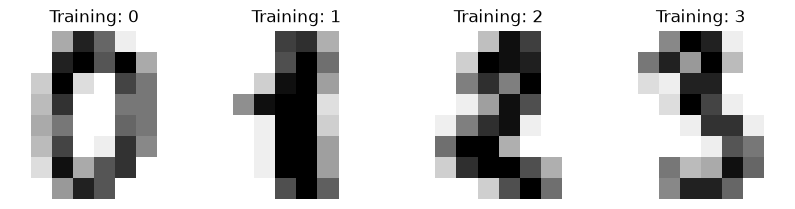

In [3]:
print("Phạm Lê Anh Khoa - 6451071035")

_, axes = plt.subplots(1, 4, figsize=(10, 3))
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Training: %i' % label)
plt.show()

### Bước 4: Chuyển đổi mỗi đối tượng hình ảnh ma trận 8x8 thành vector 1x64 và chia dữ liệu
Chia dữ liệu thành hai phần: Huấn luyện 80%, Kiểm thử 20% (shuffle=False theo hướng dẫn).

In [4]:
print("Phạm Lê Anh Khoa - 6451071035")

# To apply a classifier on this data, we need to flatten the image,
# to turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# Split data into train and test subsets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False
)

print(f"Số lượng mẫu huấn luyện: {len(X_train)}")
print(f"Số lượng mẫu kiểm thử: {len(X_test)}")

Phạm Lê Anh Khoa - 6451071035
Số lượng mẫu huấn luyện: 1437
Số lượng mẫu kiểm thử: 360


### Bước 5: Xây dựng và huấn luyện mô hình cây quyết định ID3 (`criterion='entropy'`, `random_state=33`)

In [5]:
print("Phạm Lê Anh Khoa - 6451071035")

# Create a classifier: a decision tree classifier
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)

# We learn the digits on the first part of the digits
classifier.fit(X_train, y_train)
classifier

Phạm Lê Anh Khoa - 6451071035


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",33
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

### Bước 6: Dự đoán nhãn dữ liệu cho tập kiểm thử và biểu diễn một vài kết quả dự đoán

Phạm Lê Anh Khoa - 6451071035


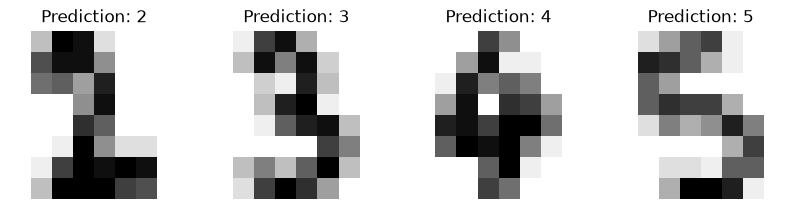

In [6]:
print("Phạm Lê Anh Khoa - 6451071035")

# Now predict the value of the digit on the second part:
predicted = classifier.predict(X_test)

_, axes = plt.subplots(1, 4, figsize=(10, 3))
images_and_predictions = list(zip(digits.images[len(digits.images) - len(X_test):], predicted))
for ax, (image, prediction) in zip(axes, images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Prediction: %i' % prediction)
plt.show()

### Bước 7: Đánh giá thông số đạt được của cây ID3 (Classification report & Confusion matrix)

Phạm Lê Anh Khoa - 6451071035
Classification report for classifier DecisionTreeClassifier(criterion='entropy', random_state=33):
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360


Confusion matrix:
[[31  0  0  0  1  0  0  0  1  2]
 [ 0 23  0  2  2  0  0  1  1  7]
 [ 1  2 26  0  0  1  0  3  

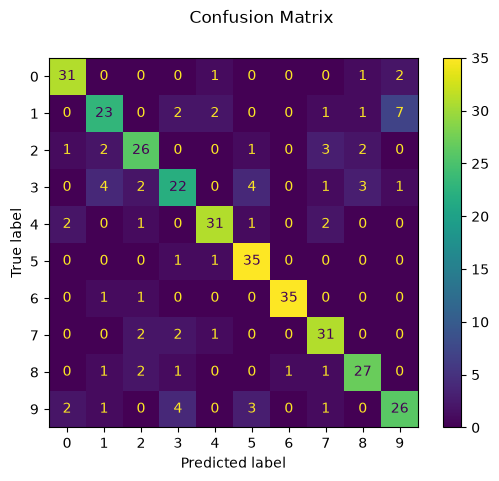

In [7]:
print("Phạm Lê Anh Khoa - 6451071035")

print("Classification report for classifier %s:\n%s\n"
      % (classifier, metrics.classification_report(y_test, predicted)))

# Biểu diễn ma trận nhầm lẫn (sử dụng ConfusionMatrixDisplay tương thích cả bản sklearn cũ và mới)
disp = metrics.ConfusionMatrixDisplay.from_predictions(y_test, predicted)
disp.figure_.suptitle("Confusion Matrix")
print("Confusion matrix:\n%s" % disp.confusion_matrix)
plt.show()

### Bước 8: Thử nghiệm nhận dạng chữ số viết tay từ file ảnh tự chụp

Phạm Lê Anh Khoa - 6451071035


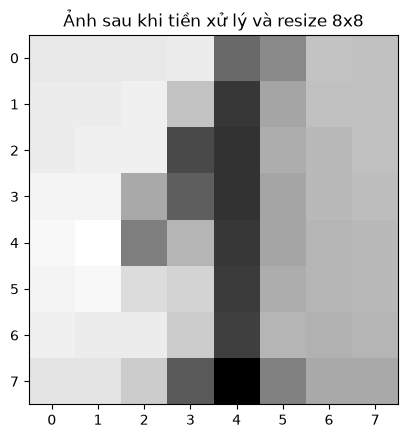

In [8]:
print("Phạm Lê Anh Khoa - 6451071035")

try:
    # Open image, convert to grayscale and resize to 8x8
    img = Image.open('Dataset/test_image_Bai7(1).jpg').convert("L").resize((8, 8))
    # Invert image (đổi chữ thành màu sáng, nền tối tương thích tập huấn luyện)
    img = ImageOps.invert(img)
    # Convert to numpy array
    im2arr = np.array(img)
    # Show
    plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
    plt.title("Ảnh sau khi tiền xử lý và resize 8x8")
    plt.show()
except FileNotFoundError:
    print("Chưa có file 'test_image_Bai7.jpg' trong thư mục. Hãy chụp hoặc vẽ số 1 lưu tên 'test_image_Bai7.jpg' để thử nghiệm.")

### Bước 9: Làm rõ nét lại bức ảnh và nhận diện bằng mô hình cây ID3

Phạm Lê Anh Khoa - 6451071035
[[  0   0   0   0 155   0   0   0   0   0   0   0 155   0   0   0   0   0
    0 155 155   0   0   0   0   0   0 155 155   0   0   0   0   0 155   0
  155   0   0   0   0   0   0   0 155   0   0   0   0   0   0   0 155   0
    0   0   0   0   0 155 155   0   0   0]]


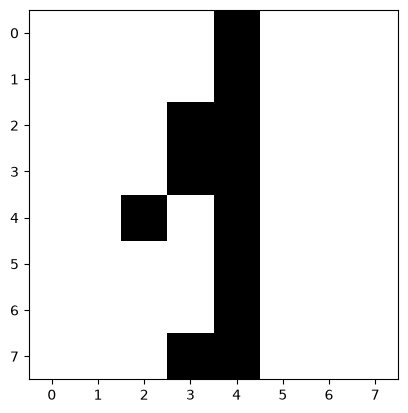

[1]


In [9]:
print("Phạm Lê Anh Khoa - 6451071035")

# Change from 2d array (8x8) to 1d array (1x64)
img1d = im2arr.reshape([1, 64]).copy()

# normailize black & white image array
# Ngưỡng phân biệt điều chỉnh theo độ sáng ảnh chụp thực tế
threshold = (img1d.max() + img1d.min()) // 2

img1d[img1d > threshold] = 155
img1d[img1d <= threshold] = 0

# In mảng 1d kiểm tra như tài liệu
print(img1d)

# After normalize
plt.imshow(img1d.reshape((8, 8)), cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

# Predict label of number
y_pred = classifier.predict(img1d)
print(y_pred)